In [1]:
# ============================================================
# WEEK 13: MODEL ERROR ANALYSIS
# CELL 1: SETUP AND LOAD PREDICTIONS
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.metrics import confusion_matrix, classification_report

# Project directories
ROOT = Path.cwd().parent

RESULTS_DIR = ROOT / "results"
MODELS_DIR = ROOT / "models"

PREDICTION_PATH = (
    RESULTS_DIR / "week9_video_level_predictions.csv"
)

device = "cuda" if __import__("torch").cuda.is_available() else "cpu"

print("WEEK 13: MODEL ERROR ANALYSIS")
print("=" * 50)

print("Project Root:", ROOT)
print("Device:", device)
print("Prediction File Exists:", PREDICTION_PATH.exists())

if not PREDICTION_PATH.exists():
    raise FileNotFoundError("Video predictions file not found!")

# Load predictions
predictions_df = pd.read_csv(PREDICTION_PATH)

print("\nTotal Videos:", len(predictions_df))
print("\nAvailable Columns:")
print(predictions_df.columns.tolist())

print("\nPrediction Data Loaded Successfully!")

WEEK 13: MODEL ERROR ANALYSIS
Project Root: c:\Users\HIMANSHU\Desktop\minor project 1\Minor-Project
Device: cuda
Prediction File Exists: True

Total Videos: 1233

Available Columns:
['video_path', 'video_id', 'true_label', 'probability_fake', 'face_count', 'predicted_label']

Prediction Data Loaded Successfully!


In [2]:
# ============================================================
# WEEK 13: MODEL ERROR ANALYSIS
# CELL 2: IDENTIFY FALSE PREDICTIONS
# ============================================================

# Copy predictions for analysis
error_df = predictions_df.copy()

# Identify prediction errors
error_df["error_type"] = "Correct"

# False Positive: Actual Real, Predicted Deepfake
error_df.loc[
    (error_df["true_label"] == 0) &
    (error_df["predicted_label"] == 1),
    "error_type"
] = "False Positive"

# False Negative: Actual Deepfake, Predicted Real
error_df.loc[
    (error_df["true_label"] == 1) &
    (error_df["predicted_label"] == 0),
    "error_type"
] = "False Negative"

# Count each category
print("ERROR ANALYSIS SUMMARY")
print("=" * 50)

print("\n", error_df["error_type"].value_counts())

# Save detailed error analysis
output_path = RESULTS_DIR / "week13_error_analysis.csv"
error_df.to_csv(output_path, index=False)

print("\nError analysis saved:", output_path)

ERROR ANALYSIS SUMMARY

 error_type
Correct           1121
False Positive     101
False Negative      11
Name: count, dtype: int64

Error analysis saved: c:\Users\HIMANSHU\Desktop\minor project 1\Minor-Project\results\week13_error_analysis.csv


In [3]:
# ============================================================
# WEEK 13: MODEL ERROR ANALYSIS
# CELL 3: INSPECT MISCLASSIFIED VIDEOS
# ============================================================

# Extract False Positive and False Negative samples
false_positives = error_df[
    error_df["error_type"] == "False Positive"
].copy()

false_negatives = error_df[
    error_df["error_type"] == "False Negative"
].copy()

# Display False Positive samples
print("FALSE POSITIVE SAMPLES")
print("=" * 60)

print(
    false_positives[
        ["video_id", "true_label", "predicted_label",
         "probability_fake", "face_count"]
    ].head(10).to_string(index=False)
)

# Display False Negative samples
print("\nFALSE NEGATIVE SAMPLES")
print("=" * 60)

print(
    false_negatives[
        ["video_id", "true_label", "predicted_label",
         "probability_fake", "face_count"]
    ].to_string(index=False)
)

# Save separate error files
false_positives.to_csv(
    RESULTS_DIR / "week13_false_positives.csv",
    index=False
)

false_negatives.to_csv(
    RESULTS_DIR / "week13_false_negatives.csv",
    index=False
)

print("\nFalse Positive videos:", len(false_positives))
print("False Negative videos:", len(false_negatives))
print("Error sample files saved successfully!")

FALSE POSITIVE SAMPLES
 video_id  true_label  predicted_label  probability_fake  face_count
 id0_0001           0                1          0.483757          10
 id0_0004           0                1          0.552127          10
id11_0001           0                1          0.460296          10
id11_0008           0                1          0.151073          10
id12_0002           0                1          0.238716          10
id12_0005           0                1          0.327838          10
id17_0006           0                1          0.771319          10
id19_0006           0                1          0.997925          10
 id1_0001           0                1          0.500486          10
 id1_0006           0                1          0.541644          10

FALSE NEGATIVE SAMPLES
      video_id  true_label  predicted_label  probability_fake  face_count
id10_id12_0008           1                0          0.125186          10
 id10_id7_0008           1                0   

In [4]:
# ============================================================
# WEEK 13: MODEL ERROR ANALYSIS
# CELL 4: CONFIDENCE ANALYSIS
# ============================================================

threshold = 0.14

print("CONFIDENCE ANALYSIS")
print("=" * 60)

# Probability statistics for each category
for category in ["Correct", "False Positive", "False Negative"]:

    subset = error_df[
        error_df["error_type"] == category
    ]

    print(f"\n{category}")
    print("-" * 40)

    print("Count:", len(subset))
    print("Mean Fake Probability:",
          round(subset["probability_fake"].mean(), 4))
    print("Minimum Probability:",
          round(subset["probability_fake"].min(), 4))
    print("Maximum Probability:",
          round(subset["probability_fake"].max(), 4))

# Save confidence summary
confidence_summary = (
    error_df.groupby("error_type")["probability_fake"]
    .agg(["count", "mean", "min", "max"])
    .reset_index()
)

confidence_summary.to_csv(
    RESULTS_DIR / "week13_confidence_analysis.csv",
    index=False
)

print("\nConfidence analysis saved successfully!")

CONFIDENCE ANALYSIS

Correct
----------------------------------------
Count: 1121
Mean Fake Probability: 0.6734
Minimum Probability: 0.0
Maximum Probability: 1.0

False Positive
----------------------------------------
Count: 101
Mean Fake Probability: 0.5181
Minimum Probability: 0.1496
Maximum Probability: 0.9995

False Negative
----------------------------------------
Count: 11
Mean Fake Probability: 0.0489
Minimum Probability: 0.002
Maximum Probability: 0.1252

Confidence analysis saved successfully!


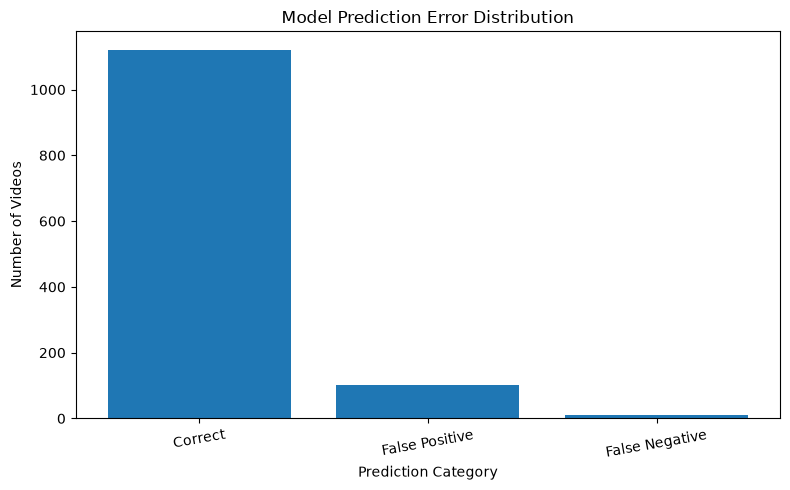

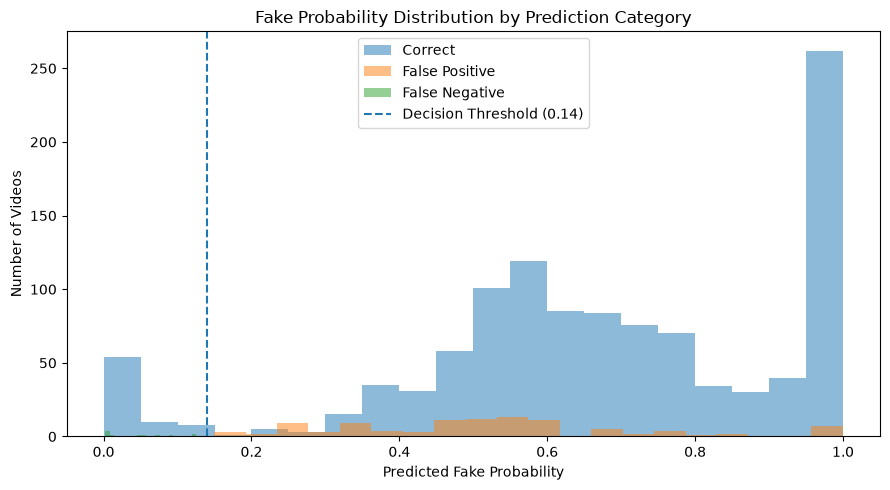

Both Week 13 graphs saved successfully!


In [5]:
# ============================================================
# WEEK 13: MODEL ERROR ANALYSIS
# CELL 5: ERROR VISUALIZATION
# ============================================================

# 1. Error category distribution
error_counts = error_df["error_type"].value_counts()

plt.figure(figsize=(8, 5))
plt.bar(error_counts.index, error_counts.values)

plt.title("Model Prediction Error Distribution")
plt.xlabel("Prediction Category")
plt.ylabel("Number of Videos")
plt.xticks(rotation=10)

plt.tight_layout()
plt.savefig(
    RESULTS_DIR / "week13_error_distribution.png",
    dpi=300
)
plt.show()


# 2. Fake probability distribution by error category
plt.figure(figsize=(9, 5))

for category in ["Correct", "False Positive", "False Negative"]:

    probabilities = error_df.loc[
        error_df["error_type"] == category,
        "probability_fake"
    ]

    plt.hist(
        probabilities,
        bins=20,
        alpha=0.5,
        label=category
    )

plt.axvline(
    x=0.14,
    linestyle="--",
    label="Decision Threshold (0.14)"
)

plt.title("Fake Probability Distribution by Prediction Category")
plt.xlabel("Predicted Fake Probability")
plt.ylabel("Number of Videos")
plt.legend()

plt.tight_layout()
plt.savefig(
    RESULTS_DIR / "week13_probability_distribution.png",
    dpi=300
)
plt.show()

print("Both Week 13 graphs saved successfully!")

In [6]:
# ============================================================
# WEEK 13: MODEL ERROR ANALYSIS
# CELL 6: FINAL SUMMARY
# ============================================================

total_videos = len(error_df)

correct = (error_df["error_type"] == "Correct").sum()
fp = (error_df["error_type"] == "False Positive").sum()
fn = (error_df["error_type"] == "False Negative").sum()

accuracy = correct / total_videos

summary = pd.DataFrame({
    "Metric": [
        "Total Videos",
        "Correct Predictions",
        "False Positives",
        "False Negatives",
        "Total Errors",
        "Prediction Accuracy"
    ],
    "Value": [
        total_videos,
        correct,
        fp,
        fn,
        fp + fn,
        round(accuracy, 4)
    ]
})

print("WEEK 13: FINAL MODEL ERROR ANALYSIS")
print("=" * 60)
print(summary.to_string(index=False))

print("\nKEY FINDINGS")
print("-" * 60)
print(f"Correct prediction rate: {accuracy * 100:.2f}%")
print(f"False Positive videos: {fp}")
print(f"False Negative videos: {fn}")

print("\nConclusion:")
print(
    "The model correctly classified most test videos. "
    "However, false positives were more frequent than false negatives. "
    "Some real videos received high fake probabilities, indicating "
    "that further investigation and improvement are required."
)

# Save final summary
summary.to_csv(
    RESULTS_DIR / "week13_final_error_summary.csv",
    index=False
)

print("\nWeek 13 final summary saved successfully!")

WEEK 13: FINAL MODEL ERROR ANALYSIS
             Metric     Value
       Total Videos 1233.0000
Correct Predictions 1121.0000
    False Positives  101.0000
    False Negatives   11.0000
       Total Errors  112.0000
Prediction Accuracy    0.9092

KEY FINDINGS
------------------------------------------------------------
Correct prediction rate: 90.92%
False Positive videos: 101
False Negative videos: 11

Conclusion:
The model correctly classified most test videos. However, false positives were more frequent than false negatives. Some real videos received high fake probabilities, indicating that further investigation and improvement are required.

Week 13 final summary saved successfully!
